## Sistemas de control: Lab 2

### Parte 1: Preparación de la Experiencia

2 states have been removed from the model
[ 7.77156117e-16+2.02507945j  7.77156117e-16-2.02507945j
 -6.55500000e-01+0.77802298j -6.55500000e-01-0.77802298j]
[-0.+2.02507945j  0.-2.02507945j]


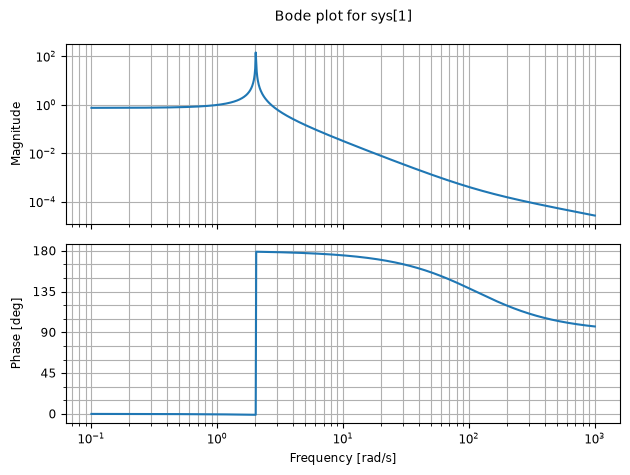

In [1]:
import control as ctrl
from numpy import linspace
import matplotlib.pyplot as plt

G = ctrl.tf([-0.02705, 0.06326], [1, 1.311, 1.035], inputs=['b'], outputs=['v'])

K = 1.311/.02705

G_lc = ctrl.tf([-0.02705, 0.06326*K],[1, 1.311-0.02705*K, 1.035+0.06326*K])

G_lc_producto = K*G/(1+K*G)
ctrl.minreal(G_lc_producto)
print(G_lc_producto.poles())

print(G_lc.poles())
G_lc.bode_plot()

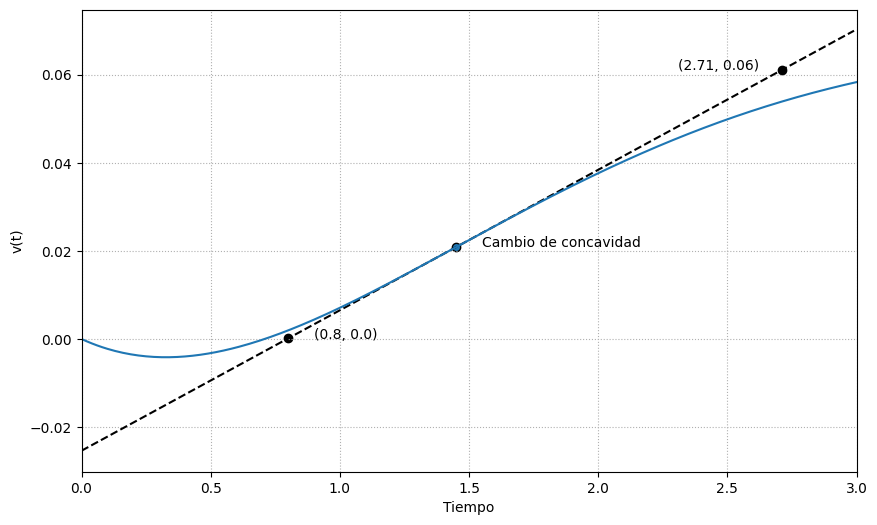

In [ ]:
from numpy import polyfit, poly1d, arange, linspace

plt.rcParams['figure.figsize'] = [10,6]

t = linspace(0,100,10000)

x, y = G.step_response(T=t)

dydx = [(y[i]-y[i-1])/(x[i]-x[i-1]) for i in range(1,len(x))]
d2ydx2 = [(dydx[i]-dydx[i-1])/(x[i]-x[i-1]) for i in range(1,len(x)-1)]

plt.xlim([0,25])

poly = polyfit(x[145:147], y[145:147], 1)

reg = []
for i in x:
    reg.append(0.03188135*i-0.0253592)

plt.plot(x[:300], reg[:300], color="#000000", linestyle='--')
# plt.plot(x, [y[-1] for i in x], color='#676767')
# plt.plot(x, [0 for i in x], color='#000000')
plt.grid(linestyle=':')
plt.xlabel('Tiempo')
plt.ylabel('v(t)')

plt.plot(x, y)
plt.scatter(x[145], y[145], edgecolor='black')
plt.text(x[145]+0.1, y[145], 'Cambio de concavidad')
plt.scatter([x[i_int_0], x[i_int_vf]], [reg[i_int_0], reg[i_int_vf]], color='black')
plt.text(x[i_int_0]+.1, reg[i_int_0], f'({round(x[i_int_0],2)}, {round(reg[i_int_0],2)})')
plt.text(x[i_int_vf]-.4, reg[i_int_vf], f'({round(x[i_int_vf],2)}, {round(reg[i_int_vf],2)})')
plt.xlim([0,3])
# plt.xticks(arange(0, 3, 0.25))

plt.savefig('tangente_zn.svg', format='svg')

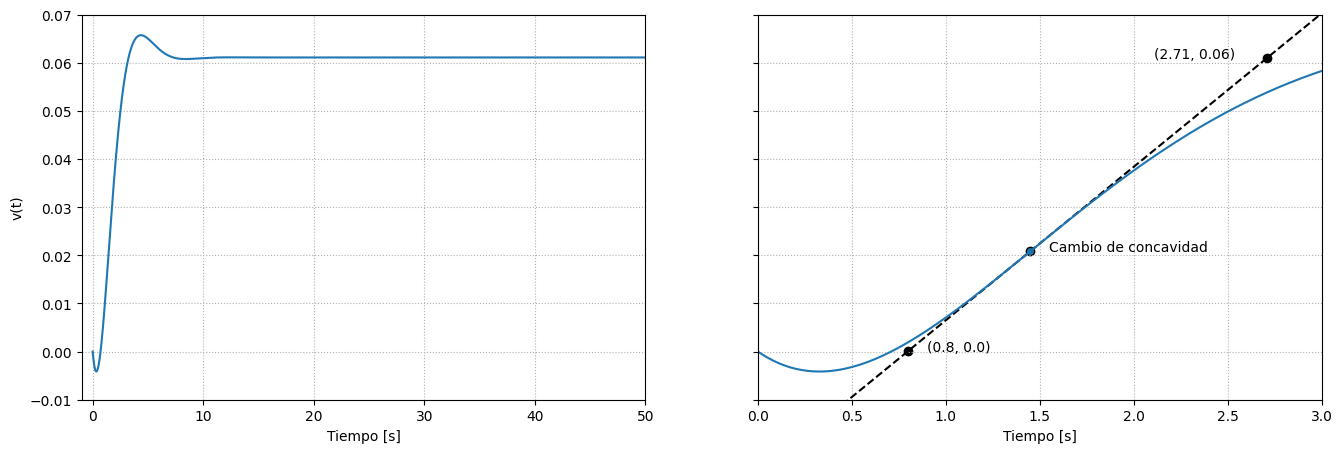

In [104]:
plt.rcParams['figure.figsize'] = [16,5]

fig, (ax1, ax2) = plt.subplots(ncols=2, sharey=True)

ax1.plot(x, y)
ax1.set_xlabel('Tiempo [s]')
ax1.set_ylabel('v(t)')
ax1.grid(linestyle=':')
ax1.set_ylim([-0.01, 0.07])
ax1.set_xlim([-1, 50])

ax2.plot(x[:300], reg[:300], color="#000000", linestyle='--')
# ax2.plot(x, [y[-1] for i in x], color='#676767')
# ax2.plot(x, [0 for i in x], color='#000000')
ax2.grid(linestyle=':')
ax2.set_xlabel('Tiempo [s]')
# ax2.set_ylabel('v(t)')

ax2.plot(x, y)
ax2.scatter(x[145], y[145], edgecolor='black')
ax2.text(x[145]+0.1, y[145], 'Cambio de concavidad')
ax2.scatter([x[i_int_0], x[i_int_vf]], [reg[i_int_0], reg[i_int_vf]], color='black')
ax2.text(x[i_int_0]+.1, reg[i_int_0], f'({round(x[i_int_0],2)}, {round(reg[i_int_0],2)})')
ax2.text(x[i_int_vf]-.6, reg[i_int_vf], f'({round(x[i_int_vf],2)}, {round(reg[i_int_vf],2)})')
ax2.set_xlim([0,3])
# ax2.xticks(arange(0, 3, 0.25))

plt.savefig('tangente_zn.svg', format='svg')

In [84]:
intersección_0 = min([abs(j)for j in reg])
intersección_vf = min([abs(j)for j in [y[-1] - i for i in reg]])

i_int_0 = [abs(j)for j in [0.03188135 * x[i] - 0.0253592 for i in range(len(x))]].index(intersección_0)
i_int_vf = [abs(j)for j in [y[-1] - i for i in reg]].index(intersección_vf)

print(x[i_int_0], x[i_int_vf] - x[i_int_0])

0.8000800080008001 1.9101910191019102


In [83]:
print(poly)
print(y[145] - (0.03188135 * x[145] - 0.0253592))

[ 0.03188135 -0.0253592 ]
1.7693351575531757e-09


3) ZN
- tau=1.95
- L=0.8
- P: k_p=2.4375
- PI k_p= 2.19375, k_i=2.666
- PID: k_p=2.925, k_i=1.6, k_p= 0.4

4) ZN
- k_cr= 45
- P_cr= 1
- P: k_p=22.5
- PI: k_p= 20.25, k_i= 24.3
- PID: k_p= 27, k_i=54, k_d= 3.375 

P kp= 2.4375
PI kp= 2.1937499999999996 ki= 0.8226562499999998
1.10994597007701
PID kp= 2.925 ki= 1.8281249999999998 kd= 1.17


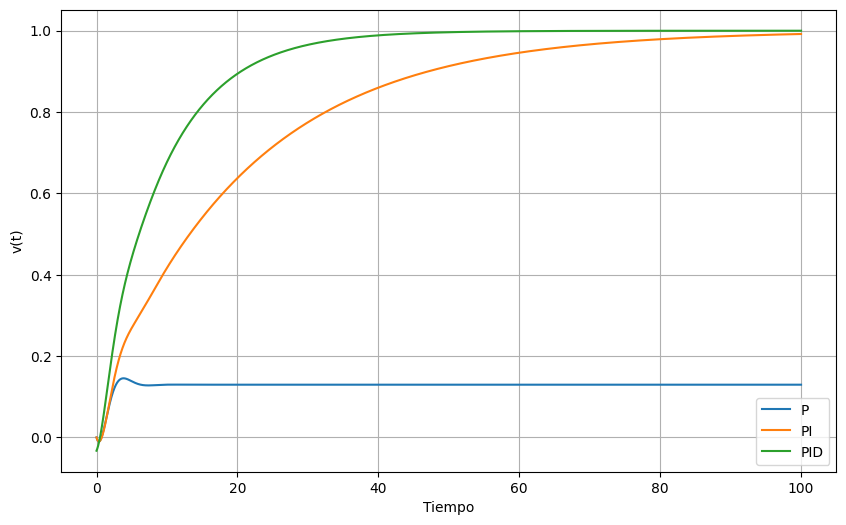

In [25]:
tau = 1.95
L = 0.8
# kp=30
# P
# kp=49
kp = tau/L
print('P','kp=',kp)
Gc_p = ctrl.tf([kp], [1]) #numerador, denominador

# PI
kp = 0.9*tau/L
Ti = L/0.3
Gc_pi = ctrl.tf([kp, kp/Ti], [1, 0])
print('PI','kp=',kp,'ki=', kp/Ti)
print(1.035+0.06326*kp-0.02705*(kp/Ti)-(0.06326*(kp/Ti))/(1.311-0.02705*kp))

# PID

kp = 1.2*tau/L
Ti = 2*L
Td = 0.5*L
print('PID','kp=',kp,'ki=', kp/Ti, 'kd=', kp*Td)
Gc_pid = ctrl.tf([kp*Td, kp, kp/Ti], [1, 0])

G_lc_p = ctrl.feedback(Gc_p*G, 1)
G_lc_pi = ctrl.feedback(Gc_pi*G, 1)
G_lc_pid = ctrl.feedback(Gc_pid*G, 1)

t = linspace(0,100,30000)

x, y_p = G_lc_p.step_response(T=t)
x, y_pi = G_lc_pi.step_response(T=t)
x, y_pid = G_lc_pid.step_response(T=t)

plt.plot(x, y_p, label='P')
plt.plot(x, y_pi, label='PI')
plt.plot(x, y_pid, label='PID')
plt.grid()
plt.xlabel('Tiempo')
plt.ylabel('v(t)')
plt.legend(loc = 'lower right')

P kp= 22.5
PI kp= 20.25 ki= 18.27067669172932
PID kp= 27.0 ki= 40.6015037593985 kd= 4.4887500000000005


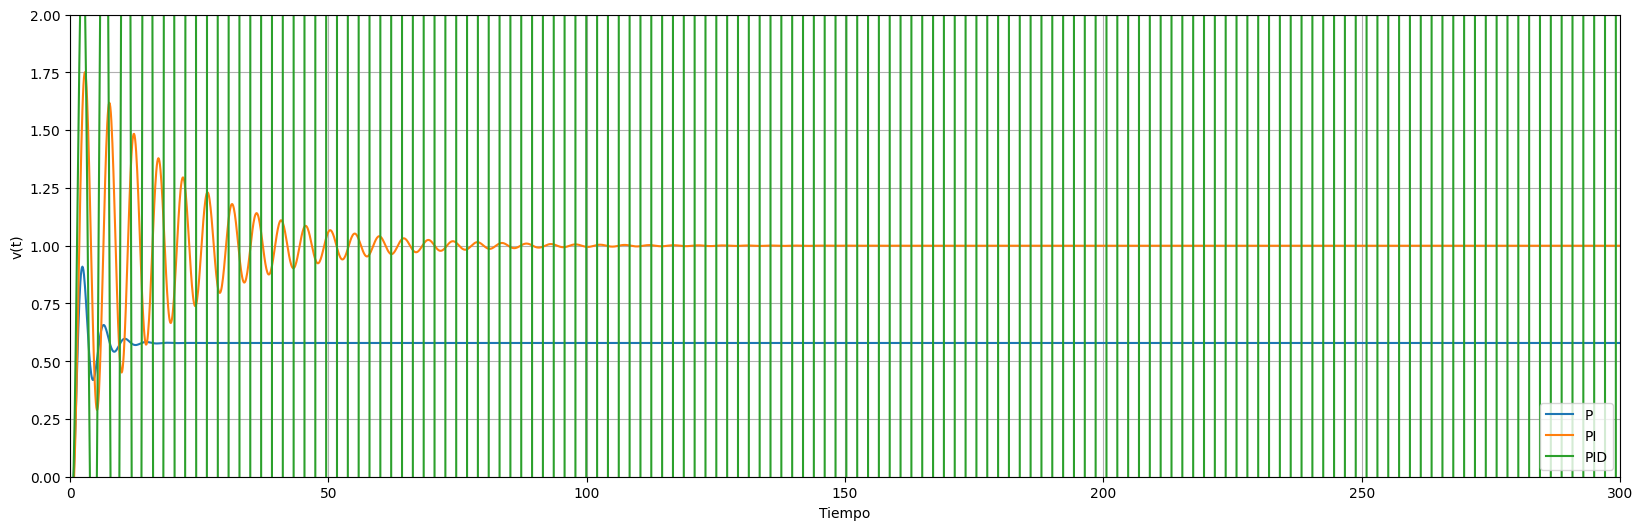

In [123]:
k_cr = 45
P_cr = 1.33 #habiamos acordado de que era 1, pero con 1 PI y PID divergen, con 1.5 al menos PI converge....

# P
kp = 0.5*k_cr
Gc_p4 = ctrl.tf([kp], [1])
print('P','kp=',kp)

# PI
kp = 0.45*k_cr
Ti = P_cr/1.2
Gc_pi4 = ctrl.tf([kp, kp/Ti], [1, 0])
print('PI','kp=',kp,'ki=', kp/Ti)
# print(1.035+0.06326*kp-0.02705*(kp/Ti)-(0.06326*(kp/Ti))/(1.311-0.02705*kp))

# PID
kp = 0.6*k_cr
Ti = 0.5*P_cr
Td = 0.125*P_cr
print('PID','kp=',kp,'ki=', kp/Ti, 'kd=', kp*Td)
Gc_pid4 = ctrl.tf([kp*Td, kp, kp/Ti], [1, 0])

G_lc_p4 = ctrl.feedback(Gc_p4*G, 1)
G_lc_pi4 = ctrl.feedback(Gc_pi4*G, 1)
G_lc_pid4 = ctrl.feedback(Gc_pid4*G, 1)

t = linspace(0,3000,30000)

x, y_p4 = G_lc_p4.step_response(T=t)
x, y_pi4 = G_lc_pi4.step_response(T=t)
x, y_pid4 = G_lc_pid4.step_response(T=t)

plt.plot(x, y_p4, label='P')
plt.plot(x, y_pi4, label='PI')
plt.plot(x, y_pid4, label='PID')
plt.grid()
plt.xlabel('Tiempo')
plt.ylabel('v(t)')
plt.xlim([0, 300])
plt.ylim([0, 2])
plt.legend(loc='lower right')


Comparación de ambos:

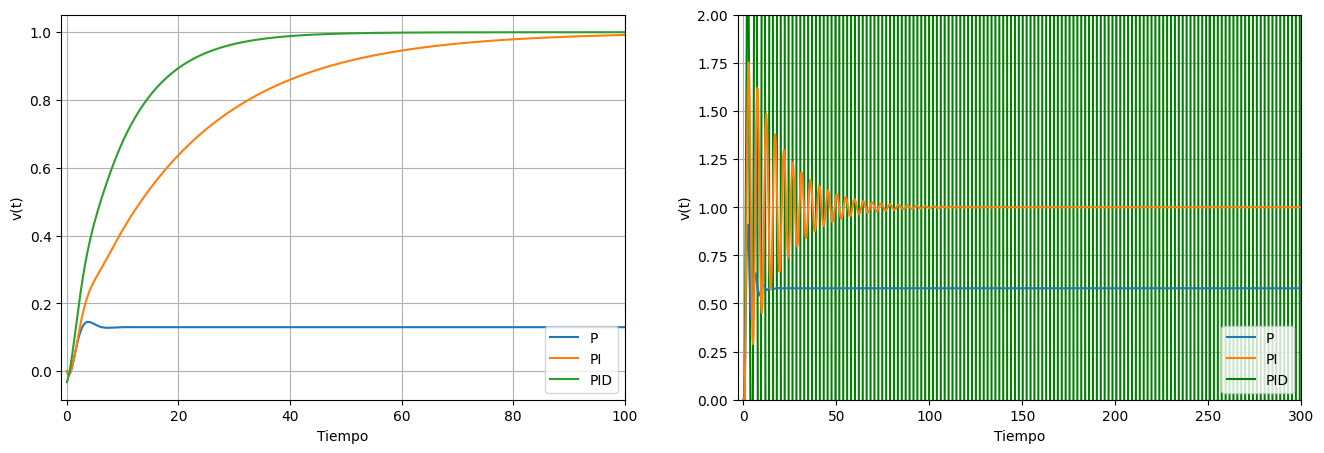

In [117]:
fig, (ax1, ax2) = plt.subplots(ncols=2)
plt.rcParams['figure.figsize'] = [20, 6]

t = linspace(0,100,30000)

x, y_p = G_lc_p.step_response(T=t)
x, y_pi = G_lc_pi.step_response(T=t)
x, y_pid = G_lc_pid.step_response(T=t)

ax1.plot(x, y_p, label='P')
ax1.plot(x, y_pi, label='PI')
ax1.plot(x, y_pid, label='PID')
ax1.grid()
ax1.set_xlabel('Tiempo')
ax1.set_ylabel('v(t)')
ax1.set_xlim([-1,100])
ax1.legend(loc = 'lower right')

t = linspace(0,300,3000)

x, y_p4 = G_lc_p4.step_response(T=t)
x, y_pi4 = G_lc_pi4.step_response(T=t)
x, y_pid4 = G_lc_pid4.step_response(T=t)

plot_pid,   = ax2.plot(x, y_pid4, label='PID', color='green')
plot_p,  = ax2.plot(x, y_p4, label='P')
plot_pi, = ax2.plot(x, y_pi4, label='PI')

ax2.grid()
ax2.set_xlabel('Tiempo')
ax2.set_ylabel('v(t)')
ax2.set_ylim([0, 2])
ax2.set_xlim([-3,300])
ax2.legend([plot_p, plot_pi, plot_pid], ['P', 'PI', 'PID'], loc='lower right')
plt.savefig('comparación_steps.svg', format='svg')

### Parte 2: Experiencia de laboratorio